# 04export: how much smoke left for the Pacific, and how much was washed out

Part A of PF5 (direct export), in tonnes. Uses the GEOS-FP files from `01event`; no downloads.

**Idea: a smoke budget for boxes.** GEOS-FP gives, at every grid point, how many kilograms of smoke cross one metre of a line per second, summed over the whole air column (the "column mass flux" of black, organic and brown carbon). Adding this up along the four sides of a box gives how much smoke enters and leaves the box. GEOS-FP also gives how much smoke sits in the column above each point, so we know how much smoke is inside the box at any time.

For a box over open ocean (no fires inside):

**smoke removed = smoke flowing in - smoke flowing out - increase of smoke inside the box**

Over the ocean, "removed" is almost entirely smoke washed out by rain (wet deposition) plus a little settling. This gives an estimate of what the storm's rain took out, even though GEOS-FP does not offer deposition in our download.

| Section | What |
|---|---|
| 2 | Map of the mean smoke flow during the event, with the budget boxes |
| 3 | Budget for each region: smoke leaving each fire region through each side |
| 4 | Budget for the Pacific corridor: inflow, outflow, change, and the implied removal by rain |

Units: tonnes (t) and tonnes per day (t/day). 1 t = 1,000 kg.

## Section 0: settings

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw" / "event"
OUT_DIR = PROJECT_DIR / "data" / "processed" / "event"
FIG_DIR = OUT_DIR / "figures"
COAST_DIR = PROJECT_DIR / "data" / "raw" / "naturalearth"

# Budget boxes as (west, east, south, north); the same boxes as 02eventmaps and 03trajectories
BOXES = {}
BOXES["Sumatra"] = (95.0, 106.0, -6.0, 4.0)  # <-
BOXES["Kalimantan"] = (108.0, 118.5, -4.5, 2.0)  # <-
BOXES["Eastern Indonesia"] = (119.0, 141.0, -9.0, 2.0)  # <-
BOXES["Pacific corridor"] = (128.0, 150.0, 3.0, 18.0)  # <-
OCEAN_BOX = "Pacific corridor"  # <- box used for the removal estimate (must have no fires inside)

BUDGET_START = "2026-09-30 00:00"  # <- start of the budget period (Choi-wan's first track point)
BUDGET_END = "2026-10-06 00:00"  # <- end of the budget period (before the storm left the corridor's latitude band far behind)
MAP_EXTENT = (90.0, 160.0, -15.0, 30.0)  # <-

# VISUAL
ARROW_STEP = 8  # <- VISUAL: one flow arrow every n grid points
ARROW_SCALE = 0.005  # <- VISUAL: smaller number = longer arrows
SIDE_COLORS = {"west": "#2a78d6", "east": "#eb6834", "south": "#1baf7a", "north": "#eda100"}  # <- VISUAL

## Section 1: imports and data

In [2]:
import json
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm

warnings.filterwarnings("ignore", message="Ambiguous reference date string")
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.facecolor"] = "#fcfcfb"
plt.rcParams["axes.facecolor"] = "#fcfcfb"
plt.rcParams["axes.edgecolor"] = "#a8a7a2"
plt.rcParams["font.size"] = 10
R = 6371000.0

names = ["bcfluxu", "bcfluxv", "ocfluxu", "ocfluxv", "brfluxu", "brfluxv", "bccmass", "occmass", "brcmass"]
g = xr.merge([xr.open_dataset(RAW_DIR / f"geosfp_{v}.nc") for v in names])
FU = (g["bcfluxu"] + g["ocfluxu"] + g["brfluxu"]).values
FV = (g["bcfluxv"] + g["ocfluxv"] + g["brfluxv"]).values
CM = (g["bccmass"] + g["occmass"] + g["brcmass"]).values
LAT = g.lat.values
LON = g.lon.values
GT = pd.to_datetime(g.time.values)
DLAT = np.deg2rad(LAT[1] - LAT[0])
DLON = np.deg2rad(LON[1] - LON[0])
print("GEOS-FP smoke flux and column mass:", FU.shape, " time", GT[0], "to", GT[-1])
print("Units: flux kg per metre per second (column total), column mass kg per m2")

track = pd.read_csv(RAW_DIR / "choiwan_track.csv")


def load_lines(path):
    lines = []
    for feat in json.loads(path.read_text(encoding="utf8"))["features"]:
        geom = feat["geometry"]
        parts = geom["coordinates"] if geom["type"] == "MultiLineString" else [geom["coordinates"]]
        lines += [np.array(p) for p in parts]
    return lines


COAST = load_lines(COAST_DIR / "ne_50m_coastline.geojson")


def draw_base(ax, extent=MAP_EXTENT):
    for line in COAST:
        ax.plot(line[:, 0], line[:, 1], color="#52514e", lw=0.5)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")
    ax.tick_params(labelsize=8, colors="#52514e")

GEOS-FP smoke flux and column mass: (80, 241, 225)  time 2026-09-28 01:30:00 to 2026-10-07 22:30:00
Units: flux kg per metre per second (column total), column mass kg per m2


## Section 2: the mean smoke flow

Arrows: mean column smoke flux over the budget period (direction and size of the smoke flow). Colour: mean smoke in the air column. Boxes: the budget boxes.

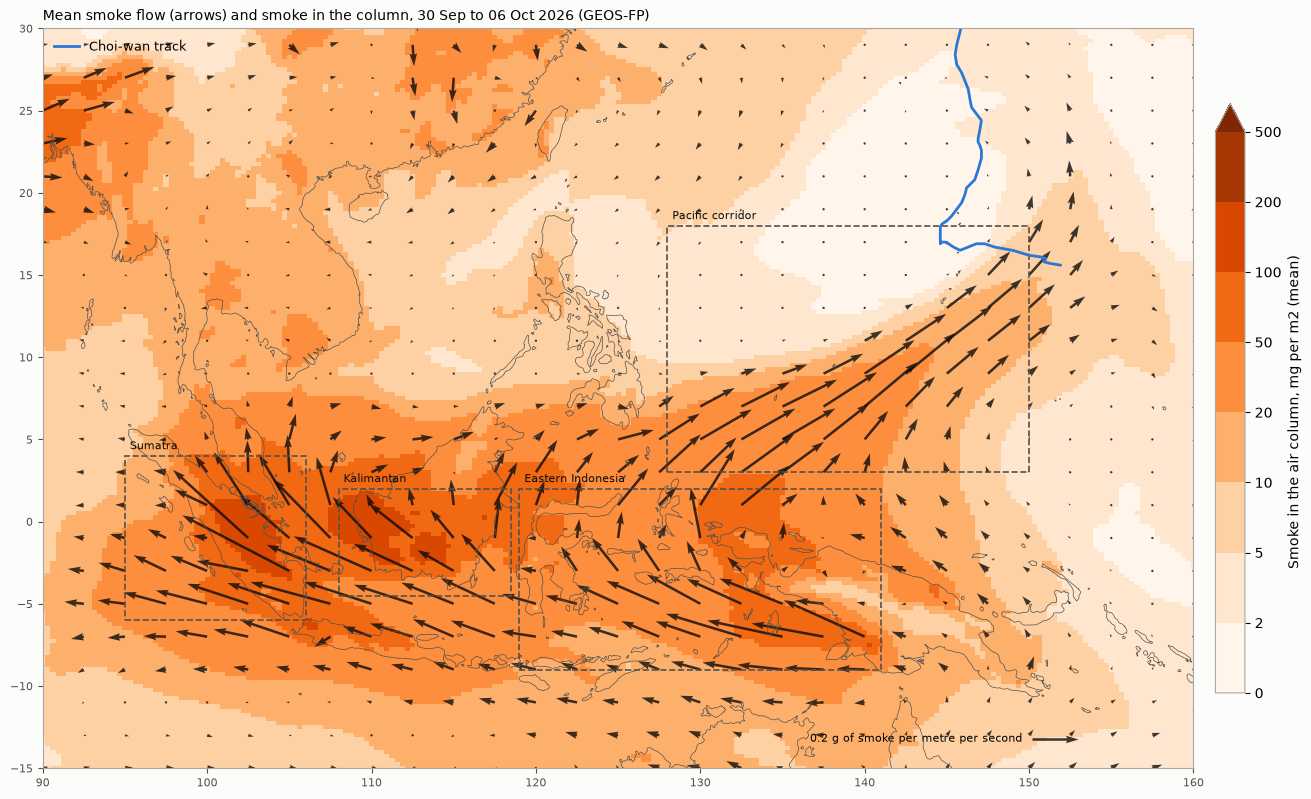

In [3]:
win = (GT >= pd.Timestamp(BUDGET_START)) & (GT < pd.Timestamp(BUDGET_END))
fu_m = FU[win].mean(axis=0)
fv_m = FV[win].mean(axis=0)
cm_m = CM[win].mean(axis=0) * 1e6
fig, ax = plt.subplots(figsize=(13, 8.5), constrained_layout=True)
levels = [0, 2, 5, 10, 20, 50, 100, 200, 500]
mesh = ax.pcolormesh(LON, LAT, cm_m, cmap="Oranges", norm=BoundaryNorm(levels, 256, extend="max"), shading="auto")
s = ARROW_STEP
q = ax.quiver(LON[::s], LAT[::s], fu_m[::s, ::s], fv_m[::s, ::s], color="#0b0b0b", scale=ARROW_SCALE, width=0.0022, alpha=0.8)
ax.quiverkey(q, 0.86, 0.04, 2e-4, "0.2 g of smoke per metre per second", labelpos="W", fontproperties={"size": 8}, color="#0b0b0b")
for name, b in BOXES.items():
    ax.add_patch(plt.Rectangle((b[0], b[2]), b[1] - b[0], b[3] - b[2], fill=False, lw=1.2, ls="--", ec="#52514e"))
    ax.text(b[0] + 0.3, b[3] + 0.4, name, fontsize=8, color="#0b0b0b")
ax.plot(track["LON"], track["LAT"], color="#2a78d6", lw=2, label="Choi-wan track")
draw_base(ax)
ax.legend(frameon=False, loc="upper left", fontsize=9)
cb = fig.colorbar(mesh, ax=ax, shrink=0.7, pad=0.01)
cb.set_label("Smoke in the air column, mg per m2 (mean)")
ax.set_title(f"Mean smoke flow (arrows) and smoke in the column, {pd.Timestamp(BUDGET_START):%d %b} to {pd.Timestamp(BUDGET_END):%d %b} 2026 (GEOS-FP)", loc="left", fontsize=10)
fig.savefig(FIG_DIR / "export_flow_map.png", dpi=110)
plt.show()

## Section 3: smoke leaving each region

For each box and each 3-hour step: smoke crossing each side (positive = leaving the box), in tonnes per day. Each side is taken along the grid line nearest to the box edge.

"Net" is the net **transport** across the sides. The fires inside a fire region add smoke that is not part of this number, so a fire region can still show a negative net when more smoke blows in from a neighbour than leaves (Sumatra in this period receives smoke from the Kalimantan and Java Sea side).

In [4]:
def box_budget(box):
    w, e, s_, n = box
    iw = int(np.abs(LON - w).argmin())
    ie = int(np.abs(LON - e).argmin())
    js = int(np.abs(LAT - s_).argmin())
    jn = int(np.abs(LAT - n).argmin())
    lat_in = slice(js, jn + 1)
    lon_in = slice(iw, ie + 1)
    dy = R * DLAT
    dx_s = R * np.cos(np.deg2rad(LAT[js])) * DLON
    dx_n = R * np.cos(np.deg2rad(LAT[jn])) * DLON
    to_t_day = 86400 / 1000
    out = pd.DataFrame({"time": GT})
    out["west"] = -FU[:, lat_in, iw].sum(axis=1) * dy * to_t_day
    out["east"] = FU[:, lat_in, ie].sum(axis=1) * dy * to_t_day
    out["south"] = -FV[:, js, lon_in].sum(axis=1) * dx_s * to_t_day
    out["north"] = FV[:, jn, lon_in].sum(axis=1) * dx_n * to_t_day
    out["net_out"] = out[["west", "east", "south", "north"]].sum(axis=1)
    area = (R ** 2) * DLAT * DLON * np.cos(np.deg2rad(LAT[lat_in]))[:, None] * np.ones((1, ie - iw + 1))
    out["mass_t"] = (CM[:, lat_in, lon_in] * area[None, :, :]).sum(axis=(1, 2)) / 1000
    return out


budgets = {name: box_budget(b) for name, b in BOXES.items()}
rows = []
for name, bud in budgets.items():
    sub = bud[win]
    row = {"box": name}
    for side in ["west", "east", "south", "north", "net_out"]:
        row[side + "_t_per_day"] = sub[side].mean()
    row["mean_mass_t"] = sub["mass_t"].mean()
    rows.append(row)
    bud.to_csv(OUT_DIR / f"budget_{name.lower().replace(' ', '_')}.csv", index=False)
export_table = pd.DataFrame(rows).set_index("box")
export_table.round(0).to_csv(OUT_DIR / "export_by_region.csv")
print(f"Mean smoke flow through each side, {pd.Timestamp(BUDGET_START):%d %b} to {pd.Timestamp(BUDGET_END):%d %b} (t/day, positive = leaving the box):")
print(export_table.round(0).to_string())

Mean smoke flow through each side, 30 Sep to 06 Oct (t/day, positive = leaving the box):
                   west_t_per_day  east_t_per_day  south_t_per_day  north_t_per_day  net_out_t_per_day  mean_mass_t
box                                                                                                                
Sumatra                    7468.0        -17748.0          -3285.0           6388.0            -7177.0      83660.0
Kalimantan                12551.0         -1366.0          -9883.0           7061.0             8363.0      68113.0
Eastern Indonesia          8466.0         -7440.0          -4839.0          25147.0            21334.0     116844.0
Pacific corridor          -7700.0          8052.0         -18818.0            122.0           -18344.0      52959.0


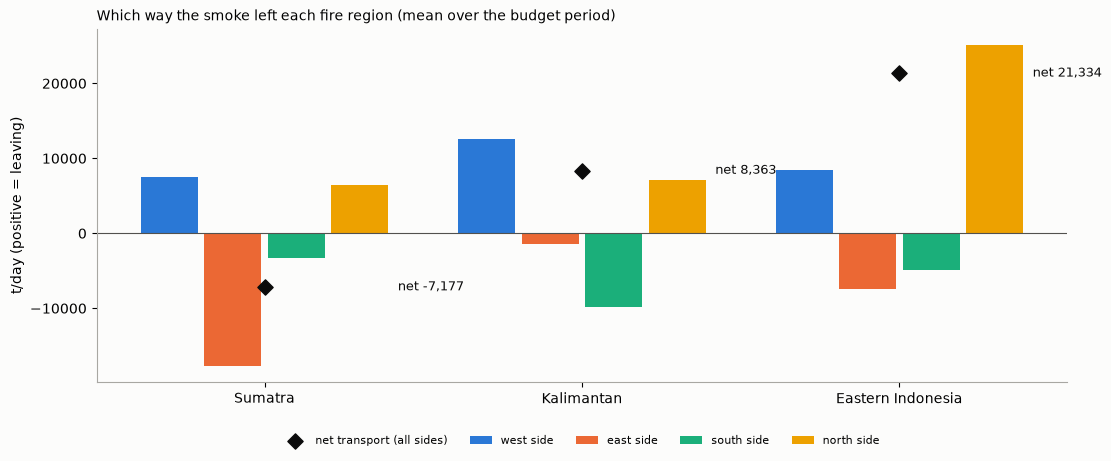

In [5]:
fire_boxes = [b for b in BOXES if b != OCEAN_BOX]
fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
x = np.arange(len(fire_boxes))
width = 0.2
for k, side in enumerate(["west", "east", "south", "north"]):
    vals = export_table.loc[fire_boxes, side + "_t_per_day"].values
    ax.bar(x + (k - 1.5) * width, vals, width=width * 0.9, color=SIDE_COLORS[side], label=f"{side} side")
ax.scatter(x, export_table.loc[fire_boxes, "net_out_t_per_day"], marker="D", s=60, color="#0b0b0b", zorder=5, label="net transport (all sides)")
for k, name in enumerate(fire_boxes):
    v = export_table.loc[name, "net_out_t_per_day"]
    ax.text(k + 0.42, v, f"net {v:,.0f}", va="center", fontsize=9, color="#0b0b0b")
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(fire_boxes)
ax.set_ylabel("t/day (positive = leaving)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_title("Which way the smoke left each fire region (mean over the budget period)", loc="left", fontsize=10)
fig.savefig(FIG_DIR / "export_by_region.png", dpi=110)
plt.show()

## Section 4: the Pacific corridor budget and the removal by rain

Inside the corridor there are no fires, so smoke can only arrive across its sides, stay, or be removed. The removal is estimated from the budget:

removal = inflow - outflow - increase in the box

Rates are 3-hour means, so the time series is smoothed with a 24-hour running mean before plotting. The total over the budget period is the honest headline number; single 3-hour values are noisy.

In [6]:
bud = budgets[OCEAN_BOX].copy()
dt_days = 3 / 24
bud["d_mass_t_per_day"] = np.gradient(bud["mass_t"].values, dt_days)
bud["inflow_t_per_day"] = -bud[["west", "east", "south", "north"]].clip(upper=0).sum(axis=1)
bud["outflow_t_per_day"] = bud[["west", "east", "south", "north"]].clip(lower=0).sum(axis=1)
bud["removal_t_per_day"] = bud["inflow_t_per_day"] - bud["outflow_t_per_day"] - bud["d_mass_t_per_day"]
bud.to_csv(OUT_DIR / "budget_corridor_removal.csv", index=False)

sub = bud[win]
days = (pd.Timestamp(BUDGET_END) - pd.Timestamp(BUDGET_START)).total_seconds() / 86400
inflow_total = sub["inflow_t_per_day"].mean() * days
outflow_total = sub["outflow_t_per_day"].mean() * days
mass_change = sub["mass_t"].iloc[-1] - sub["mass_t"].iloc[0]
removal_total = inflow_total - outflow_total - mass_change
print(f"Pacific corridor smoke budget, {pd.Timestamp(BUDGET_START):%d %b} to {pd.Timestamp(BUDGET_END):%d %b} ({days:.0f} days):")
print(f"  smoke flowing in      {inflow_total:10,.0f} t")
print(f"  smoke flowing out     {outflow_total:10,.0f} t")
print(f"  change inside the box {mass_change:10,.0f} t  (from {sub['mass_t'].iloc[0]:,.0f} to {sub['mass_t'].iloc[-1]:,.0f} t)")
print(f"  implied removal       {removal_total:10,.0f} t  ({100 * removal_total / inflow_total:.0f}% of the inflow)")
print()
side_totals = (-sub[["west", "east", "south", "north"]].clip(upper=0)).mean() * days
print("Inflow by side (t):", side_totals.round(0).to_dict())

Pacific corridor smoke budget, 30 Sep to 06 Oct (6 days):
  smoke flowing in         161,782 t
  smoke flowing out         51,718 t
  change inside the box     28,994 t  (from 31,937 to 60,931 t)
  implied removal           81,070 t  (50% of the inflow)

Inflow by side (t): {'west': 46199.0, 'east': 0.0, 'south': 112909.0, 'north': 2673.0}


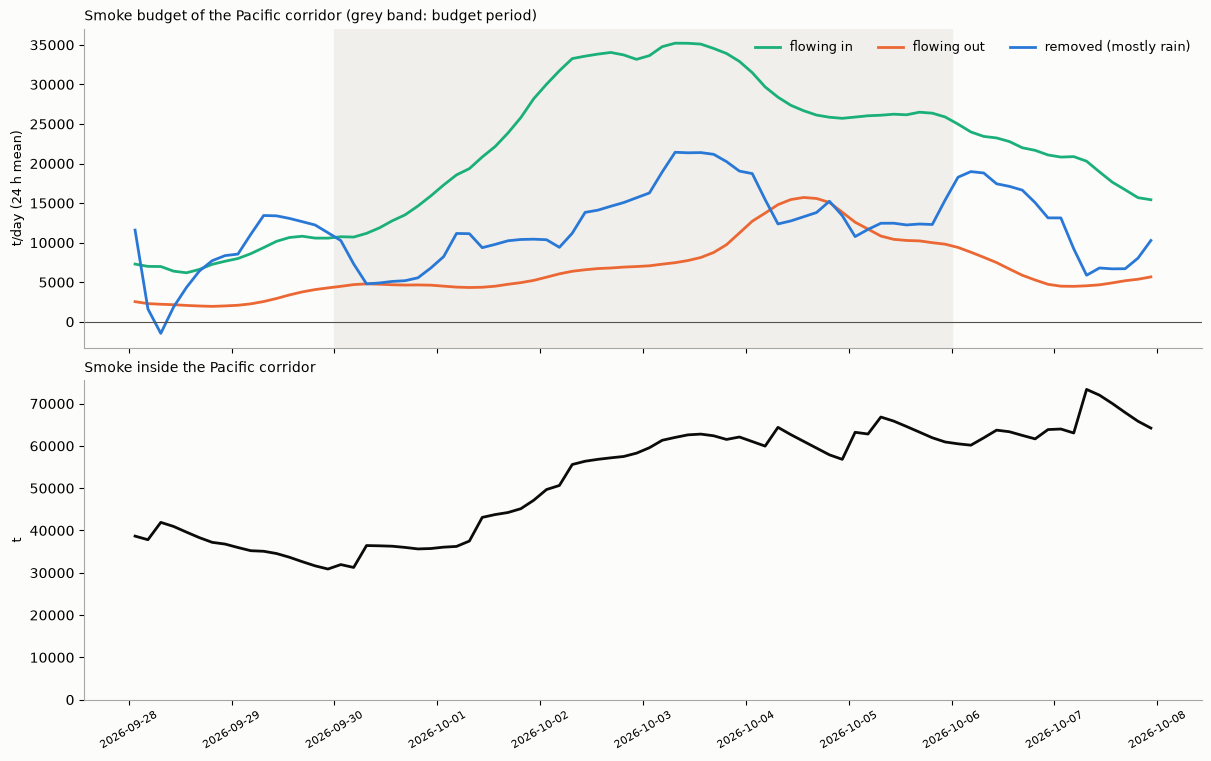

In [7]:
roll = bud.set_index("time")[["inflow_t_per_day", "outflow_t_per_day", "d_mass_t_per_day", "removal_t_per_day", "mass_t"]].rolling("24h").mean()
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, constrained_layout=True)
ax = axes[0]
ax.plot(roll.index, roll["inflow_t_per_day"], color="#1baf7a", lw=2, label="flowing in")
ax.plot(roll.index, roll["outflow_t_per_day"], color="#eb6834", lw=2, label="flowing out")
ax.plot(roll.index, roll["removal_t_per_day"], color="#2a78d6", lw=2, label="removed (mostly rain)")
ax.axhline(0, color="#52514e", lw=0.8)
ax.axvspan(pd.Timestamp(BUDGET_START), pd.Timestamp(BUDGET_END), color="#f0efec", zorder=0)
ax.set_ylabel("t/day (24 h mean)", fontsize=9)
ax.legend(frameon=False, fontsize=9, ncol=3)
ax.set_title(f"Smoke budget of the {OCEAN_BOX} (grey band: budget period)", loc="left", fontsize=10)
ax = axes[1]
ax.plot(bud["time"], bud["mass_t"], color="#0b0b0b", lw=2)
ax.set_ylabel("t", fontsize=9)
ax.set_ylim(bottom=0)
ax.set_title(f"Smoke inside the {OCEAN_BOX}", loc="left", fontsize=10)
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
axes[1].tick_params(axis="x", rotation=30, labelsize=8)
fig.savefig(FIG_DIR / "export_corridor_budget.png", dpi=110)
plt.show()

**Reading the numbers honestly**

- These are model numbers (GEOS-FP), not measurements. GEOS-FP takes in satellite aerosol data, but smoke amounts depend on its fire emission estimates; CAMS would give different tonnes (Section 3 of 02eventmaps showed the two models differ by up to a factor of about 1.5 over some regions).
- The fluxes are 3-hour means taken on the grid lines nearest to the box edges, so the budget does not close exactly. Small negative "removal" in single 3-hour steps is noise; the period total is the number to quote.
- "Removed" includes all losses inside the box: mostly wet deposition (rain), plus dry settling and any numerical leftover.

___
**END**